# Pneumonia detection from paediatric chest X-rays (v2)

**Author:** Mohammed Afeez Olamilekan · [GitHub: NKASG](https://github.com/NKASG)

This is a rebuilt version of my original pneumonia classifier. The first version (a 6-layer CNN trained from
scratch) reached **92.6% training accuracy but only 76.8% test accuracy**, and its validation loss rose every
epoch, a clear case of overfitting. It was also judged on accuracy alone, which is misleading on a dataset
with about three pneumonia images for every normal one.

What changes in v2:

| Problem in v1 | Fix in v2 |
| --- | --- |
| Validation set of only 16 images | Validation set of ~15% of training data, **split by patient** so no patient appears in both |
| Class imbalance (≈1 : 2.9 normal : pneumonia) ignored | Balanced class weights in the loss |
| Small CNN trained from scratch overfits | **DenseNet121** pretrained on ImageNet (the CheXNet architecture), fine-tuned in two stages |
| Vertical flips in augmentation (anatomically unrealistic) | Small rotations, shifts, zoom and contrast changes only |
| Accuracy only | ROC-AUC, sensitivity, specificity, precision, F1, confusion matrix |
| Decision threshold fixed at 0.5 | Threshold chosen on the **validation** set, then applied unchanged to the test set |
| No explanation of predictions | **Grad-CAM** heatmaps showing which lung regions drove each prediction |

**Dataset:** Kermany et al. (2018), *Chest X-Ray Images (Pneumonia)*, the Guangzhou Women and Children's Medical
Center paediatric set distributed on Kaggle (`paultimothymooney/chest-xray-pneumonia`). The official `test`
folder is used **only once**, at the end.

In [1]:
import json, os, re, hashlib, time
from pathlib import Path
from concurrent.futures import ProcessPoolExecutor

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (roc_auc_score, roc_curve, confusion_matrix, precision_recall_fscore_support,
                             accuracy_score, average_precision_score)

os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
import tensorflow as tf
import keras
from keras import layers

SEED = 42
keras.utils.set_random_seed(SEED)

# Paths. On Colab: download the Kaggle dataset and point DATA_DIR at the extracted `chest_xray` folder.
DATA_DIR = Path(os.environ.get("DATA_DIR", "chest_xray"))
OUT_DIR = Path(os.environ.get("OUT_DIR", "outputs")); OUT_DIR.mkdir(exist_ok=True, parents=True)
WEIGHTS = os.environ.get("DENSENET_WEIGHTS", "imagenet")   # local .h5 path or "imagenet"
SMOKE = int(os.environ.get("SMOKE", "0"))                  # >0 = quick test on a small subset
IMG = 224
BATCH = 32
print("TensorFlow", tf.__version__, "| Keras", keras.__version__)

I0000 00:00:1793632722.508744    2753 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1793632724.161932    2753 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TensorFlow 2.21.0 | Keras 3.15.1


## 1. Load and cache the images
The originals are around 2000×1800 pixels. Each one is resized once to 224×224 grayscale and kept in memory,
so training doesn't decode JPEGs every epoch. Patient IDs come from the file names
(`person1000_bacteria_2931.jpeg` → `person1000`, `IM-0115-0001.jpeg` → `IM-0115`).

In [2]:
def patient_id(fname):
    stem = Path(fname).stem
    m = re.match(r"(person\d+)_", stem)
    return m.group(1) if m else re.sub(r"-\d+$", "", stem)

def load_image(path):
    arr = np.asarray(Image.open(path).convert("L").resize((IMG, IMG), Image.BILINEAR), dtype=np.uint8)
    return arr, hashlib.md5(arr.tobytes()).hexdigest()

rows = []
for split in ["train", "val", "test"]:
    for label, cls in enumerate(["NORMAL", "PNEUMONIA"]):
        for p in sorted((DATA_DIR / split / cls).glob("*.jp*g")):
            rows.append(dict(path=str(p), file=p.name, orig_split=split, label=label, cls=cls,
                             subtype=("" if label == 0 else "bacterial" if "bacteria" in p.name else "viral"),
                             patient=f"{cls}:{patient_id(p.name)}"))
meta = pd.DataFrame(rows)
with ProcessPoolExecutor() as ex:
    res = list(ex.map(load_image, meta.path, chunksize=64))
X_all = np.stack([r[0] for r in res]); meta["hash"] = [r[1] for r in res]
print(meta.groupby(["orig_split", "cls"]).size().unstack())

cls         NORMAL  PNEUMONIA
orig_split                   
test           234        390
train         1341       3875
val              8          8


## 2. Check for data leakage
Before training, confirm that no test image also appears in the training data, either as an exact copy or
as a near-copy (compared on 16×16 thumbnails).

In [3]:
assert meta.groupby("hash").orig_split.nunique().max() == 1, "identical image found in two splits"
thumbs = np.stack([np.asarray(Image.fromarray(x).resize((16, 16)), np.float32).ravel() for x in X_all])
thumbs = (thumbs - thumbs.mean(1, keepdims=True)) / (thumbs.std(1, keepdims=True) + 1e-6)
te_idx = np.where(meta.orig_split == "test")[0]; tr_idx = np.where(meta.orig_split != "test")[0]
max_corr = ((thumbs[te_idx] @ thumbs[tr_idx].T) / thumbs.shape[1]).max(1)
print(f"Exact cross-split duplicates: 0 | test images with a near-copy in training (r > 0.99): {(max_corr > 0.99).sum()}")

Exact cross-split duplicates: 0 | test images with a near-copy in training (r > 0.99): 0


## 3. Patient-level train / validation split
The official 16-image `val` folder is merged into the training data. A new validation set of about 15% is then
drawn **by patient**, so the same child's X-rays never appear in both training and validation. The class
balance is kept the same in both.

In [4]:
dev = meta[meta.orig_split != "test"].reset_index()
sgkf = StratifiedGroupKFold(n_splits=7, shuffle=True, random_state=SEED)
tr_rows, va_rows = next(sgkf.split(dev, dev.label, groups=dev.patient))
idx_tr, idx_va = dev.loc[tr_rows, "index"].values, dev.loc[va_rows, "index"].values
idx_te = meta.index[meta.orig_split == "test"].values
assert not set(meta.patient[idx_tr]) & set(meta.patient[idx_va])

if SMOKE:
    rng = np.random.default_rng(SEED)
    idx_tr, idx_va, idx_te = (rng.choice(i, min(SMOKE, len(i)), replace=False) for i in (idx_tr, idx_va, idx_te))

summary = pd.DataFrame({name: meta.loc[i, "cls"].value_counts().reindex(["NORMAL", "PNEUMONIA"]) for name, i in
                        [("train", idx_tr), ("validation", idx_va), ("test", idx_te)]}).T
summary["patients"] = [meta.patient[i].nunique() for i in (idx_tr, idx_va, idx_te)]
print(summary)

y_tr, y_va, y_te = (meta.label.values[i] for i in (idx_tr, idx_va, idx_te))
cw = compute_class_weight("balanced", classes=np.array([0, 1]), y=y_tr)
class_weight = {0: float(cw[0]), 1: float(cw[1])}
print("class weights:", {k: round(v, 3) for k, v in class_weight.items()})

cls         NORMAL  PNEUMONIA  patients
train         1156       3328      2509
validation     193        555       419
test           234        390       431
class weights: {0: 1.939, 1: 0.674}


## 4. Input pipeline and augmentation
Augmentations are kept realistic for chest X-rays: rotation up to ±7°, shifts up to 5%, zoom up to 10%,
and mild contrast changes. There are **no flips**, since the heart is on the left. Images are normalised the
way DenseNet121 expects.

In [5]:
augment = keras.Sequential([
    layers.RandomRotation(0.02, fill_mode="constant"),
    layers.RandomTranslation(0.05, 0.05, fill_mode="constant"),
    layers.RandomZoom(0.1, fill_mode="constant"),
    layers.RandomContrast(0.1),
], name="augment")

def make_ds(idx, y, training):
    ds = tf.data.Dataset.from_tensor_slices((X_all[idx][..., None], y.astype("float32")))
    if training:
        ds = ds.shuffle(len(idx), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.batch(BATCH)
    def prep(x, t):
        x = tf.image.grayscale_to_rgb(tf.cast(x, tf.float32))
        if training:
            x = augment(x, training=True)
        return keras.applications.densenet.preprocess_input(x), t
    return ds.map(prep, num_parallel_calls=tf.data.AUTOTUNE).prefetch(tf.data.AUTOTUNE)

ds_tr, ds_va, ds_te = make_ds(idx_tr, y_tr, True), make_ds(idx_va, y_va, False), make_ds(idx_te, y_te, False)

## 5. Model: DenseNet121 + a small classification head
DenseNet121 is the architecture used by CheXNet (Rajpurkar et al., 2017). Training runs in two stages:
1. **Stage 1:** keep the pretrained backbone frozen and train only the new head.
2. **Stage 2:** unfreeze the last dense block (`conv5`) and fine-tune with a low learning rate. BatchNorm
   layers stay frozen so their ImageNet statistics aren't disturbed by small batches.

Early stopping watches **validation ROC-AUC** and restores the best epoch.

In [6]:
base = keras.applications.DenseNet121(include_top=False, weights=WEIGHTS, input_shape=(IMG, IMG, 3))
base.trainable = False
inp = keras.Input((IMG, IMG, 3))
feat = base(inp, training=False)
x = layers.GlobalAveragePooling2D()(feat)
x = layers.Dropout(0.3)(x)
out = layers.Dense(1, activation="sigmoid")(x)
model = keras.Model(inp, out)

metrics = [keras.metrics.AUC(name="auc"), keras.metrics.BinaryAccuracy(name="acc"),
           keras.metrics.Recall(name="sensitivity")]
E1, E2 = (1, 1) if SMOKE else (2, 8)

model.compile(keras.optimizers.Adam(1e-3), "binary_crossentropy", metrics=metrics)
t0 = time.time()
h1 = model.fit(ds_tr, validation_data=ds_va, epochs=E1, class_weight=class_weight, verbose=2)

for layer in base.layers:
    layer.trainable = layer.name.startswith("conv5") and not isinstance(layer, layers.BatchNormalization)
model.compile(keras.optimizers.Adam(1e-4), "binary_crossentropy", metrics=metrics)
callbacks = [keras.callbacks.EarlyStopping("val_auc", mode="max", patience=3, restore_best_weights=True),
             keras.callbacks.ReduceLROnPlateau("val_auc", mode="max", factor=0.3, patience=1, min_lr=1e-6)]
h2 = model.fit(ds_tr, validation_data=ds_va, epochs=E2, class_weight=class_weight, callbacks=callbacks, verbose=2)
print(f"training time: {(time.time() - t0) / 60:.1f} min")
model.save(OUT_DIR / "pneumonia_densenet121.keras")

Epoch 1/2


/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


141/141 - 332s - 2s/step - acc: 0.7924 - auc: 0.8881 - loss: 0.4293 - sensitivity: 0.7867 - val_acc: 0.9024 - val_auc: 0.9714 - val_loss: 0.2763 - val_sensitivity: 0.8883


Epoch 2/2


141/141 - 305s - 2s/step - acc: 0.8903 - auc: 0.9619 - loss: 0.2700 - sensitivity: 0.8834 - val_acc: 0.9251 - val_auc: 0.9787 - val_loss: 0.2057 - val_sensitivity: 0.9189


Epoch 1/8


... (12 outputs left out)

141/141 - 332s - 2s/step - acc: 0.9797 - auc: 0.9988 - loss: 0.0429 - sensitivity: 0.9775 - val_acc: 0.9706 - val_auc: 0.9956 - val_loss: 0.0873 - val_sensitivity: 0.9640 - learning_rate: 9.0000e-06


Epoch 8/8


141/141 - 373s - 3s/step - acc: 0.9833 - auc: 0.9988 - loss: 0.0440 - sensitivity: 0.9823 - val_acc: 0.9719 - val_auc: 0.9957 - val_loss: 0.0783 - val_sensitivity: 0.9676 - learning_rate: 9.0000e-06


training time: 57.5 min


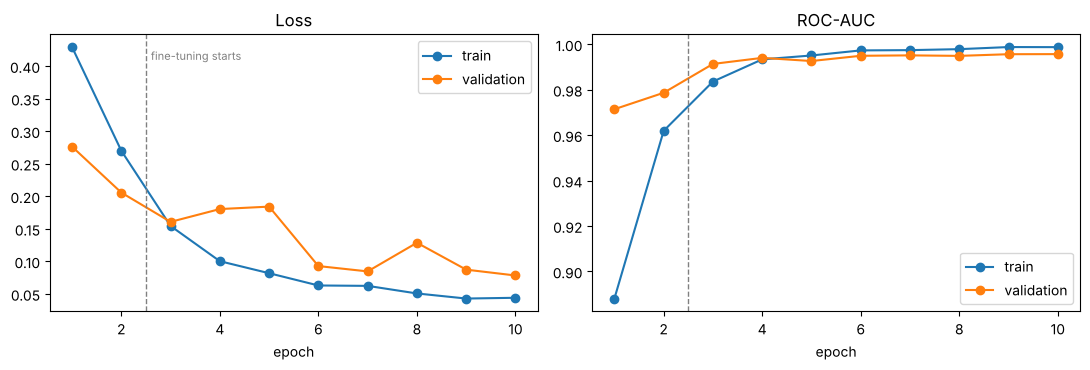

          acc     auc    loss  sensitivity  val_acc  val_auc  val_loss  val_sensitivity               stage  learning_rate
epoch                                                                                                                     
1      0.7924  0.8881  0.4293       0.7867   0.9024   0.9714    0.2763           0.8883        1: head only            NaN
2      0.8903  0.9619  0.2700       0.8834   0.9251   0.9787    0.2057           0.9189        1: head only            NaN
3      0.9367  0.9836  0.1544       0.9338   0.9345   0.9914    0.1606           0.9207  2: fine-tune conv5         0.0001
4      0.9596  0.9934  0.1003       0.9582   0.9251   0.9940    0.1804           0.8991  2: fine-tune conv5         0.0001
5      0.9686  0.9951  0.0818       0.9669   0.9385   0.9926    0.1841           0.9171  2: fine-tune conv5         0.0001
6      0.9764  0.9973  0.0629       0.9742   0.9679   0.9950    0.0928           0.9622  2: fine-tune conv5         0.0000
7      0.9741  0

In [7]:
hist = pd.concat([pd.DataFrame(h1.history).assign(stage="1: head only"),
                  pd.DataFrame(h2.history).assign(stage="2: fine-tune conv5")], ignore_index=True)
hist.index = np.arange(1, len(hist) + 1); hist.index.name = "epoch"
hist.to_csv(OUT_DIR / "history.csv")
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for a, (m, title) in zip(ax, [("loss", "Loss"), ("auc", "ROC-AUC")]):
    a.plot(hist.index, hist[m], "o-", label="train"); a.plot(hist.index, hist["val_" + m], "o-", label="validation")
    a.axvline(len(h1.history["loss"]) + 0.5, color="grey", ls="--", lw=1); a.set_title(title); a.set_xlabel("epoch")
    a.legend()
ax[0].text(len(h1.history["loss"]) + 0.6, ax[0].get_ylim()[1] * 0.95, "fine-tuning starts", fontsize=8, color="grey", va="top")
plt.tight_layout(); plt.savefig(OUT_DIR / "training_curves.png", dpi=150); plt.show()
print(hist.round(4).to_string())

## 6. Choose the decision threshold on the validation set
A screening tool should rarely miss pneumonia, but it shouldn't flag every normal X-ray either. The threshold
is set where Youden's J (sensitivity + specificity − 1) is highest **on validation**, then frozen. The test set
plays no part in choosing it.

In [7]:
p_va = model.predict(ds_va, verbose=0).ravel()
fpr, tpr, thr = roc_curve(y_va, p_va)
best = np.argmax(tpr - fpr)
THRESHOLD = float(np.clip(thr[best], 1e-6, 1 - 1e-6))
print(f"validation AUC = {roc_auc_score(y_va, p_va):.4f} | chosen threshold = {THRESHOLD:.3f} "
      f"(val sensitivity {tpr[best]:.3f}, specificity {1 - fpr[best]:.3f})")

validation AUC = 0.9968 | chosen threshold = 0.419 (val sensitivity 0.977, specificity 0.979)


## 7. Final evaluation on the held-out test set (run once)

In [8]:
p_te = model.predict(ds_te, verbose=0).ravel()

def report(y, p, t):
    pred = (p >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    prec, rec, f1, _ = precision_recall_fscore_support(y, pred, average="binary", zero_division=0)
    return dict(threshold=round(t, 3), roc_auc=roc_auc_score(y, p), pr_auc=average_precision_score(y, p),
                accuracy=accuracy_score(y, pred), sensitivity=tp / (tp + fn), specificity=tn / (tn + fp),
                precision=prec, f1=f1, tp=int(tp), fn=int(fn), tn=int(tn), fp=int(fp))

res = pd.DataFrame([report(y_te, p_te, THRESHOLD), report(y_te, p_te, 0.5)],
                   index=["validation-chosen threshold", "default 0.5 threshold"])
print(res.round(4).T.to_string())

# 95% bootstrap confidence intervals (2,000 resamples of the test set)
rng = np.random.default_rng(SEED); boot = []
for _ in range(2000):
    s = rng.integers(0, len(y_te), len(y_te))
    if len(np.unique(y_te[s])) == 2:
        r = report(y_te[s], p_te[s], THRESHOLD); boot.append([r[k] for k in ["roc_auc", "accuracy", "sensitivity", "specificity", "f1"]])
ci = np.percentile(np.array(boot), [2.5, 97.5], axis=0)
ci_tab = pd.DataFrame(ci.T, index=["roc_auc", "accuracy", "sensitivity", "specificity", "f1"], columns=["2.5%", "97.5%"])
print("\n95% bootstrap CIs (test set, chosen threshold):\n", ci_tab.round(4).to_string())

pd.DataFrame({"file": meta.file[idx_te].values, "label": y_te, "subtype": meta.subtype[idx_te].values,
              "p_pneumonia": p_te}).to_csv(OUT_DIR / "test_predictions.csv", index=False)
json.dump({"test": res.loc["validation-chosen threshold"].to_dict(), "test_at_0.5": res.loc["default 0.5 threshold"].to_dict(),
           "ci95": ci_tab.to_dict(orient="index"), "threshold": THRESHOLD,
           "val_auc": float(roc_auc_score(y_va, p_va)), "split_summary": summary.to_dict(orient="index")},
          open(OUT_DIR / "metrics.json", "w"), indent=2, default=float)

             validation-chosen threshold  default 0.5 threshold
threshold                         0.4190                 0.5000
roc_auc                           0.9697                 0.9697
pr_auc                            0.9754                 0.9754
accuracy                          0.8814                 0.8894
sensitivity                       0.9949                 0.9897
specificity                       0.6923                 0.7222
precision                         0.8435                 0.8559
f1                                0.9129                 0.9180
tp                              388.0000               386.0000
fn                                2.0000                 4.0000
tn                              162.0000               169.0000
fp                               72.0000                65.0000



95% bootstrap CIs (test set, chosen threshold):
                2.5%   97.5%
roc_auc      0.9552  0.9818
accuracy     0.8574  0.9054
sensitivity  0.9871  1.0000
specificity  0.6359  0.7511
f1           0.8928  0.9313


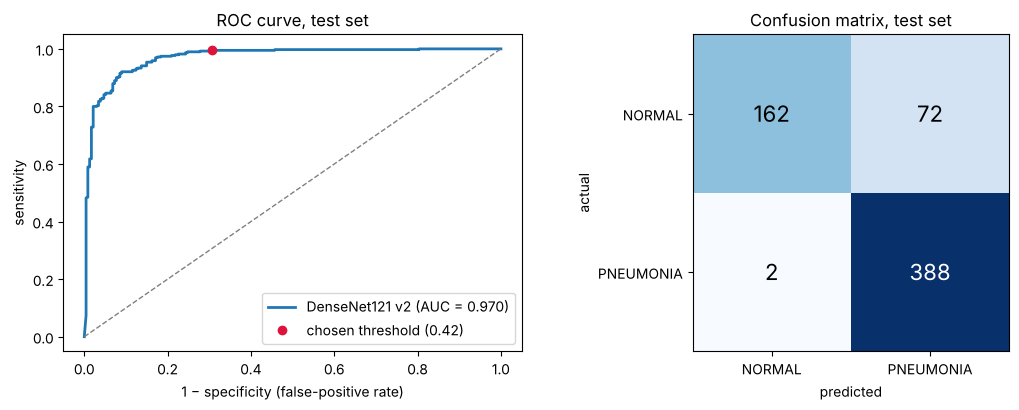

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
f, t, _ = roc_curve(y_te, p_te)
ax[0].plot(f, t, lw=2, label=f"DenseNet121 v2 (AUC = {res.iloc[0].roc_auc:.3f})")
ax[0].plot([0, 1], [0, 1], "--", color="grey", lw=1)
r0 = res.iloc[0]; ax[0].plot(1 - r0.specificity, r0.sensitivity, "o", color="crimson", label=f"chosen threshold ({THRESHOLD:.2f})")
ax[0].set_xlabel("1 − specificity (false-positive rate)"); ax[0].set_ylabel("sensitivity"); ax[0].set_title("ROC curve, test set"); ax[0].legend(loc="lower right")
cm = np.array([[r0.tn, r0.fp], [r0.fn, r0.tp]])
ax[1].imshow(cm, cmap="Blues")
for (i, j), v in np.ndenumerate(cm):
    ax[1].text(j, i, int(v), ha="center", va="center", fontsize=16, color="white" if v > cm.max() / 2 else "black")
ax[1].set_xticks([0, 1], ["NORMAL", "PNEUMONIA"]); ax[1].set_yticks([0, 1], ["NORMAL", "PNEUMONIA"])
ax[1].set_xlabel("predicted"); ax[1].set_ylabel("actual"); ax[1].set_title("Confusion matrix, test set")
plt.tight_layout(); plt.savefig(OUT_DIR / "roc_confusion.png", dpi=150); plt.show()

### Error analysis by pneumonia type

In [10]:
te_df = pd.DataFrame({"subtype": meta.subtype[idx_te].values, "y": y_te, "pred": (p_te >= THRESHOLD).astype(int)})
te_df["group"] = te_df.subtype.replace("", "normal")
by = te_df.groupby("group").apply(lambda d: pd.Series({"n": len(d), "correct": (d.y == d.pred).mean()}), include_groups=False)
print(by.round(3).to_string())

               n  correct
group                    
bacterial  242.0    0.996
normal     234.0    0.692
viral      148.0    0.993


## 8. Grad-CAM: where is the model looking?
Grad-CAM (Selvaraju et al., 2017) highlights the image regions that pushed the model towards the class it
predicted. A trustworthy model should focus on the lung fields, not on text markers such as the "R" side label,
image edges or the abdomen.

Gradients are taken with respect to the **logit** (the value before the sigmoid). On confident predictions the
sigmoid saturates and its gradient is almost zero, which would give empty heatmaps.

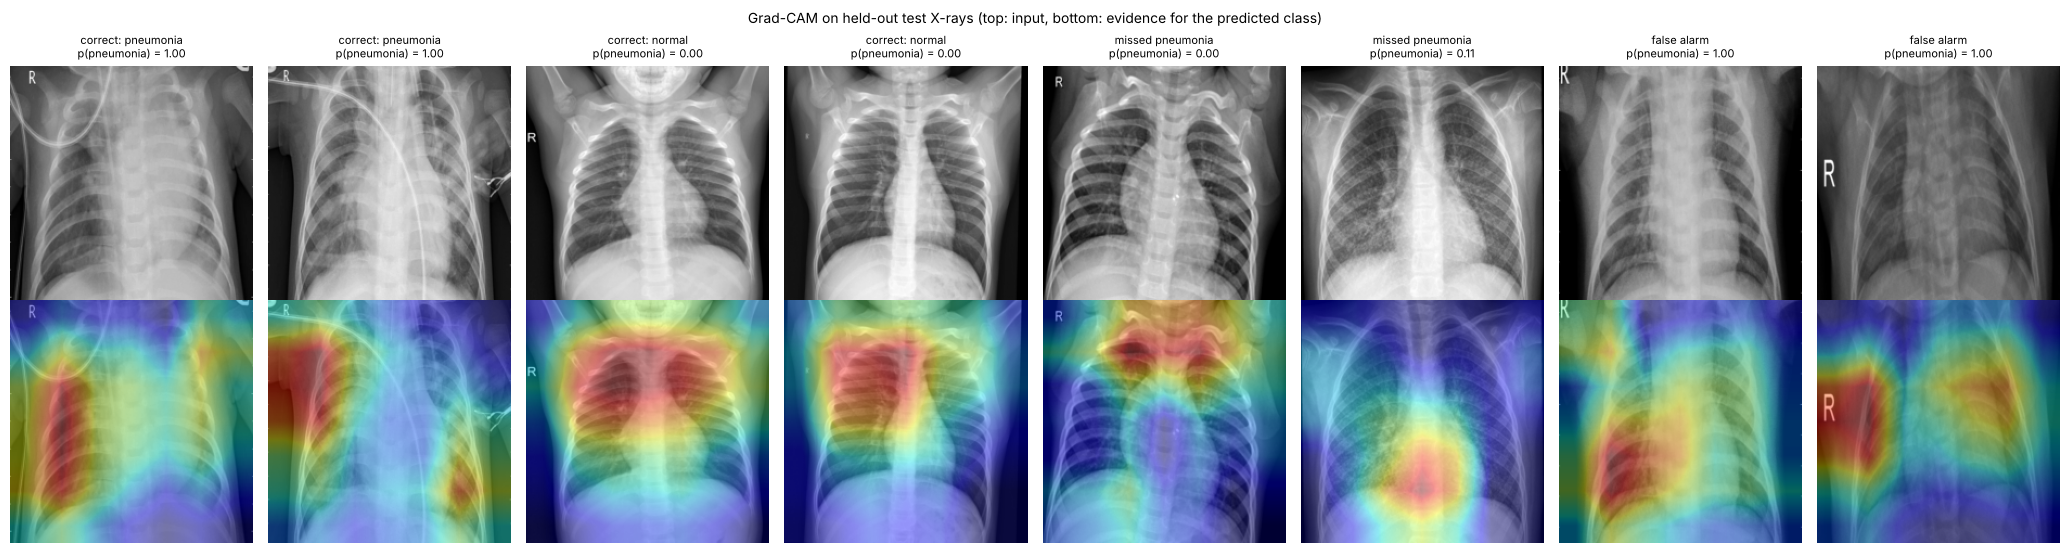

In [11]:
inner = model.get_layer(base.name)          # DenseNet121 backbone; its output is the last conv feature map
dense = model.layers[-1]                    # final Dense(1, sigmoid)

def gradcam_batch(imgs_uint8):
    """Grad-CAM for the predicted class of each image. Returns (cams in [0,1] at 224x224, p_pneumonia)."""
    x = keras.applications.densenet.preprocess_input(np.repeat(imgs_uint8[..., None].astype("float32"), 3, -1))
    conv = tf.convert_to_tensor(inner(x, training=False))   # forward pass outside the tape keeps memory low
    with tf.GradientTape() as tape:
        tape.watch(conv)
        logit = tf.matmul(tf.reduce_mean(conv, axis=(1, 2)), dense.kernel) + dense.bias
        prob = tf.sigmoid(logit)
        sign = tf.where(prob >= THRESHOLD, 1.0, -1.0)          # explain the class that was predicted
        target = tf.reduce_sum(sign * logit)
    g = tape.gradient(target, conv)
    cams = tf.nn.relu(tf.reduce_sum(conv * tf.reduce_mean(g, axis=(1, 2), keepdims=True), -1)).numpy()
    cams = np.stack([np.asarray(Image.fromarray(c / (c.max() + 1e-8)).resize((IMG, IMG), Image.BILINEAR)) for c in cams])
    return cams, prob.numpy().ravel()

def gradcam(img_uint8):
    cams, p = gradcam_batch(img_uint8[None]); return cams[0], float(p[0])

pred_te = (p_te >= THRESHOLD).astype(int)
picks = []
for name, mask, order in [("correct: pneumonia", (y_te == 1) & (pred_te == 1), -p_te),
                          ("correct: normal", (y_te == 0) & (pred_te == 0), p_te),
                          ("missed pneumonia", (y_te == 1) & (pred_te == 0), p_te),
                          ("false alarm", (y_te == 0) & (pred_te == 1), -p_te)]:
    cand = np.where(mask)[0]; cand = cand[np.argsort(order[cand])][:2]
    picks += [(name, c) for c in cand]
fig, axes = plt.subplots(2, len(picks), figsize=(2.6 * len(picks), 5.6))
for k, (name, c) in enumerate(picks):
    img = X_all[idx_te[c]]; cam, p = gradcam(img)
    axes[0, k].imshow(img, cmap="gray"); axes[0, k].set_title(f"{name}\np(pneumonia) = {p:.2f}", fontsize=8)
    axes[1, k].imshow(img, cmap="gray"); axes[1, k].imshow(cam, cmap="jet", alpha=0.4)
    for a in axes[:, k]: a.axis("off")
plt.suptitle("Grad-CAM on held-out test X-rays (top: input, bottom: evidence for the predicted class)", fontsize=10)
plt.tight_layout(); plt.savefig(OUT_DIR / "gradcam.png", dpi=150); plt.show()

### Does the model look at the lungs or at the image border?
Example images can be cherry-picked, so this measures attention across **all 624 test images**: the share of
each Grad-CAM heatmap that falls in the outer 15% border of the image, where side markers ("R"), text and
collimation edges sit. The lungs are in the central region. If heatmaps were spread evenly, about 51% would
fall in the border, because that's how much of the image area it covers.

In [12]:
cams_te = np.concatenate([gradcam_batch(X_all[idx_te[i:i + 16]])[0] for i in range(0, len(idx_te), 16)])
m = int(0.15 * IMG); inner_mask = np.zeros((IMG, IMG), bool); inner_mask[m:-m, m:-m] = True
border_share = 1 - (cams_te * inner_mask).sum((1, 2)) / (cams_te.sum((1, 2)) + 1e-8)
outcome = np.select([(y_te == 1) & (pred_te == 1), (y_te == 0) & (pred_te == 0), (y_te == 1) & (pred_te == 0)],
                    ["correct pneumonia", "correct normal", "missed pneumonia"], "false alarm")
att = pd.DataFrame({"outcome": outcome, "border_share": border_share})
att_tab = att.groupby("outcome").border_share.agg(n="size", mean_border_share="mean",
                                                   share_mostly_border=lambda s: (s > 0.5).mean())
print(f"border area = {1 - inner_mask.mean():.0%} of the image\n")
print(att_tab.round(3).to_string())
att_tab.to_csv(OUT_DIR / "gradcam_border_attention.csv")

border area = 50% of the image

                     n  mean_border_share  share_mostly_border
outcome                                                       
correct normal     162              0.423                0.185
correct pneumonia  388              0.425                0.052
false alarm         72              0.411                0.167
missed pneumonia     2              0.389                0.000


**Reading the result.**
- **Focus is mostly on the lungs.** On average about 42% of the heatmap weight falls in the border, below the
  51% expected if attention were spread evenly. For correct pneumonia calls, only about 5% of heatmaps are
  mostly in the border.
- **False alarms look like correct calls.** They average about 41% border weight, the same as correct
  predictions, so on the whole they are *not* caused by markers or edges. The "R"-marker example above is a
  real but individual case.
- **Normal X-rays lean on the border more often.** About 17–19% of normal-class heatmaps (correct or wrong)
  are mostly in the border, a weakness worth fixing. The next experiment would be to mask the side markers
  and crop to the lung fields.

## 9. Results summary and limitations
The summary below is generated from the numbers above. See the README for discussion.

In [13]:
r = res.iloc[0]
print(f"""Held-out test set ({len(y_te)} X-rays: {int((y_te == 0).sum())} normal, {int((y_te == 1).sum())} pneumonia)
  ROC-AUC      {r.roc_auc:.3f}  (95% CI {ci_tab.loc['roc_auc', '2.5%']:.3f}-{ci_tab.loc['roc_auc', '97.5%']:.3f})
  Accuracy     {r.accuracy:.3f}  (v1 model: 0.768)
  Sensitivity  {r.sensitivity:.3f}  ({int(r.tp)} of {int(r.tp + r.fn)} pneumonia cases detected)
  Specificity  {r.specificity:.3f}  ({int(r.tn)} of {int(r.tn + r.fp)} normal X-rays correctly cleared)
  F1           {r.f1:.3f}
Threshold {THRESHOLD:.3f}, chosen on validation only.""")

Held-out test set (624 X-rays: 234 normal, 390 pneumonia)
  ROC-AUC      0.970  (95% CI 0.955-0.982)
  Accuracy     0.881  (v1 model: 0.768)
  Sensitivity  0.995  (388 of 390 pneumonia cases detected)
  Specificity  0.692  (162 of 234 normal X-rays correctly cleared)
  F1           0.913
Threshold 0.419, chosen on validation only.


**Limitations**
- **Single-centre, paediatric data.** All images come from one hospital in Guangzhou (patients aged 1–5). The
  model has not been tested on adults or on other hospitals' scanners, where performance usually drops.
- **Label noise.** The labels are clinical diagnoses from the original study, not a radiologist consensus
  per image.
- **Specificity drops between validation and test.** At the same threshold, specificity is about 0.98 on the
  patient-held-out validation set but about 0.69 on the official test folder, while sensitivity hardly changes.
  So the normal X-rays in the test folder look different from the normal X-rays in training. The model learned
  cues that don't carry over, which is a dataset-shift problem rather than overfitting. Recalibrating the
  threshold on a small labelled sample from the new source is the usual remedy. Tuning it on the test set would
  be cheating, so it isn't done here.
- **Shortcut risk.** Grad-CAM shows some predictions driven by the "R" side marker or the image border (see
  section 8). Cropping or masking markers, and testing on an external dataset, are the next steps.
- **Not a medical device.** This is a research and learning project, not for clinical use.